In [1]:
import pandas as pd
import numpy as np
import os
from pathlib import Path
import tqdm
import random

from scipy.stats import pearsonr
from scipy.stats import mannwhitneyu

import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor 
import networkx as nx
from networkx.algorithms import approximation

import shap
shap.initjs()

/home1/jinyiy/.local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Frequency of IAR and SAR

In [8]:
IAR_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/IAR_score_covid.csv")

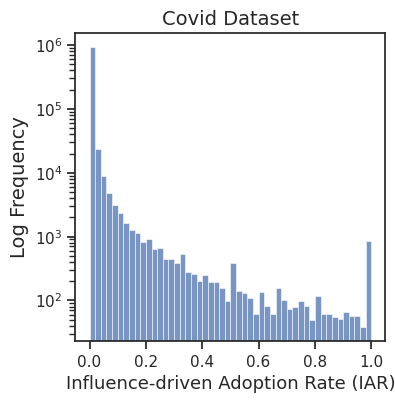

In [9]:
#plt.rcParams['font.family'] = 'Verdana'
plt.figure(figsize=(4, 4))
sns.set(style='ticks')

sns.histplot(data=IAR_df, x='IAR', bins=50)
plt.xlabel('Influence-driven Adoption Rate (IAR)', fontsize=13)
plt.ylabel('Log Frequency', fontsize=14)
plt.yscale('log')
plt.title('Covid Dataset', fontsize=14)
plt.savefig('img/IAR_freq_covid.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
SAR_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/SAR_score_covid.csv")

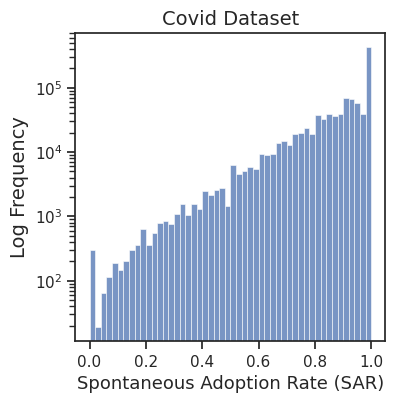

In [16]:
plt.figure(figsize=(4, 4))
sns.set(style='ticks')

sns.histplot(data=SAR_df, x='SAR', bins=50)
plt.xlabel('Spontaneous Adoption Rate (SAR)', fontsize=13)
plt.ylabel('Log Frequency', fontsize=14)
plt.yscale('log')
plt.title('Covid Dataset', fontsize=14)
plt.savefig('img/SAR_freq_covid.png', dpi=300, bbox_inches='tight')
plt.show()

### Individual level friendship paradox

In [14]:
H_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/H_df_all_IAR_election.csv")

/tmp/SLURM_23131728/ipykernel_63993/4220224289.py:5: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, 900)


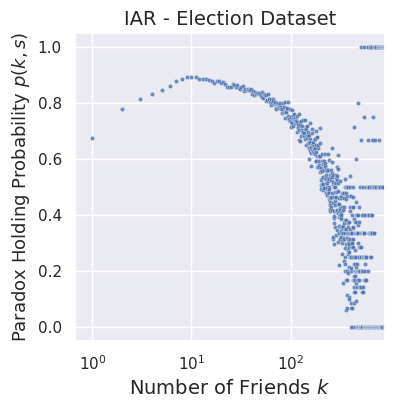

In [15]:
plt.figure(figsize=(4, 4))
sns.set(style='darkgrid')
sns.scatterplot(data=H_df, x='k_neighbors', y='H', alpha=0.8, s=10)  # Create the scatter plot
plt.xscale('log')
plt.xlim(0, 900)
plt.xlabel('Number of Friends $k$', fontsize=14)
plt.ylabel('Paradox Holding Probability $p(k,s)$', fontsize=13)
plt.title('IAR - Election Dataset', fontsize=14)
plt.savefig('img/GFP_IAR_election.png', dpi=500, bbox_inches='tight')
plt.show()

In [10]:
H_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/H_df_all_SAR_election.csv")

/tmp/SLURM_23131728/ipykernel_63993/334051235.py:5: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, 900)


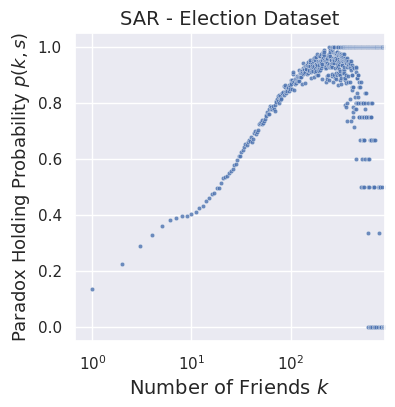

In [11]:
plt.figure(figsize=(4, 4))
sns.set(style='darkgrid')
sns.scatterplot(data=H_df, x='k_neighbors', y='H', alpha=0.8, s=10)  # Create the scatter plot
plt.xscale('log')
plt.xlim(0, 900)
plt.xlabel('Number of Friends $k$', fontsize=14)
plt.ylabel('Paradox Holding Probability $p(k,s)$', fontsize=13)
plt.title('SAR - Election Dataset', fontsize=14)
plt.savefig('img/GFP_SAR_election.png', dpi=500, bbox_inches='tight')
plt.show()

In [17]:
H_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/H_df_all_IAR_covid.csv")

/tmp/SLURM_23131728/ipykernel_63993/3708060505.py:5: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, 900)


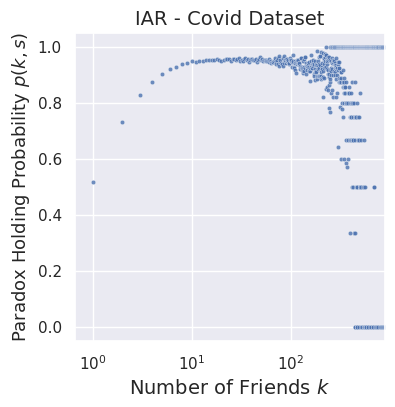

In [18]:
plt.figure(figsize=(4, 4))
sns.set(style='darkgrid')
sns.scatterplot(data=H_df, x='k_neighbors', y='H', alpha=0.8, s=10)  # Create the scatter plot
plt.xscale('log')
plt.xlim(0, 900)
plt.xlabel('Number of Friends $k$', fontsize=14)
plt.ylabel('Paradox Holding Probability $p(k,s)$', fontsize=13)
plt.title('IAR - Covid Dataset', fontsize=14)
plt.savefig('img/GFP_IAR_covid.png', dpi=500, bbox_inches='tight')
plt.show()

In [20]:
H_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/H_df_all_SAR_covid.csv")

/tmp/SLURM_23131728/ipykernel_63993/1206581755.py:5: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, 900)


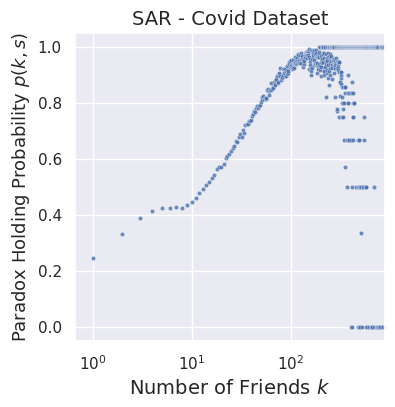

In [21]:
plt.figure(figsize=(4, 4))
sns.set(style='darkgrid')
sns.scatterplot(data=H_df, x='k_neighbors', y='H', alpha=0.8, s=10)  # Create the scatter plot
plt.xscale('log')
plt.xlim(0, 900)
plt.xlabel('Number of Friends $k$', fontsize=14)
plt.ylabel('Paradox Holding Probability $p(k,s)$', fontsize=13)
plt.title('SAR - Covid Dataset', fontsize=14)
plt.savefig('img/GFP_SAR_covid.png', dpi=500, bbox_inches='tight')
plt.show()

### Plotting $p(k,s)$

In [9]:
df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/friendship_paradox/p(k,s)_df_all_interaction_IAR_election.csv")

/tmp/SLURM_23913887/ipykernel_45448/4271615068.py:18: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['IAR_1'], iar_bins, labels=[f'{x:.9f}' for x in iar_bins[:-1]]),
/tmp/SLURM_23913887/ipykernel_45448/4271615068.py:18: FutureWarning: The provided callable <function mean at 0x7f22240bbd80> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['IAR_1'], iar_bins, labels=[f'{x:.9f}' for x in iar_bins[:-1]]),


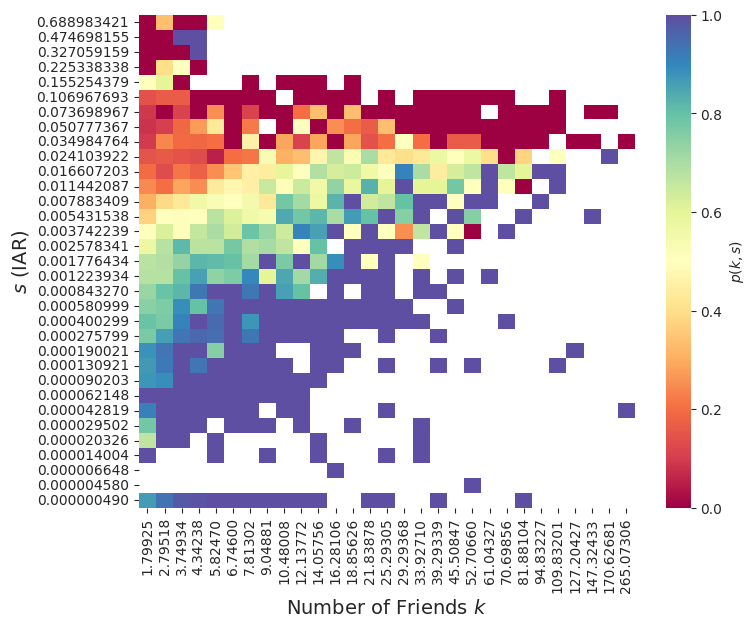

In [10]:
# Replace zeros and negative values with a small positive value (for log scale visualization)
min_positive_value = df[df['IAR_1'] > 0]['IAR_1'].min() / 10
df['IAR_1'] = df['IAR_1'].replace(to_replace=0, value=min_positive_value)

# Similarly for 'k_neighbors'
min_positive_value_k = df[df['k_neighbors'] > 0]['k_neighbors'].min() / 10
df['k_neighbors'] = df['k_neighbors'].replace(to_replace=0, value=min_positive_value_k)

# Convert 'FP' from boolean to numeric for calculation
df['FP'] = df['FP'].astype(int)

# Generating bins for 'k_neighbors' and 'IAR_1' in log scale
k_bins = np.logspace(np.log10(df['k_neighbors'].min()), np.log10(df['k_neighbors'].max()), 40)
iar_bins = np.logspace(np.log10(df['IAR_1'].min()), np.log10(df['IAR_1'].max()), 40)

# Creating a pivot table to calculate the proportion of 'FP' == True
# Not rounding labels, using more unique labels
pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['IAR_1'], iar_bins, labels=[f'{x:.9f}' for x in iar_bins[:-1]]),
                             columns=pd.cut(df['k_neighbors'], k_bins, labels=[f'{x:.5f}' for x in k_bins[:-1]]),
                             aggfunc=np.mean)

# Creating the heatmap
plt.figure(figsize=(8, 6.4))
sns.set_style("ticks")
ax = plt.gca()
sns.heatmap(pivot_table, annot=False, cmap="Spectral", cbar_kws={'label': '$p(k,s)$'})

# # Set log scale for axes
# ax.set_xscale('log')
# ax.set_yscale('log')

# Manually setting x-axis ticks
# xticks = [10**i for i in range(4)]  # 10^0 to 10^3
# ax.set_xticks(xticks)
# ax.set_xticklabels([f"$10^{i}$" for i in range(4)])  # Use LaTeX formatting for powers of 10

ax.set_xlabel('Number of Friends $k$', fontsize=14)
ax.set_ylabel('$s$ (IAR)', fontsize=14)
ax.invert_yaxis()
# ax.set_xticks([])
# ax.set_yticks([])

plt.savefig('img/IAR_heatmap_election.png', dpi=1000, bbox_inches='tight')
plt.show()

In [11]:
df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/friendship_paradox/p(k,s)_df_all_interaction_SAR_election.csv")

/tmp/SLURM_23913887/ipykernel_45448/1967467342.py:18: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['SAR_1'], sar_bins, labels=[f'{x:.9f}' for x in sar_bins[:-1]]),
/tmp/SLURM_23913887/ipykernel_45448/1967467342.py:18: FutureWarning: The provided callable <function mean at 0x7f22240bbd80> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['SAR_1'], sar_bins, labels=[f'{x:.9f}' for x in sar_bins[:-1]]),


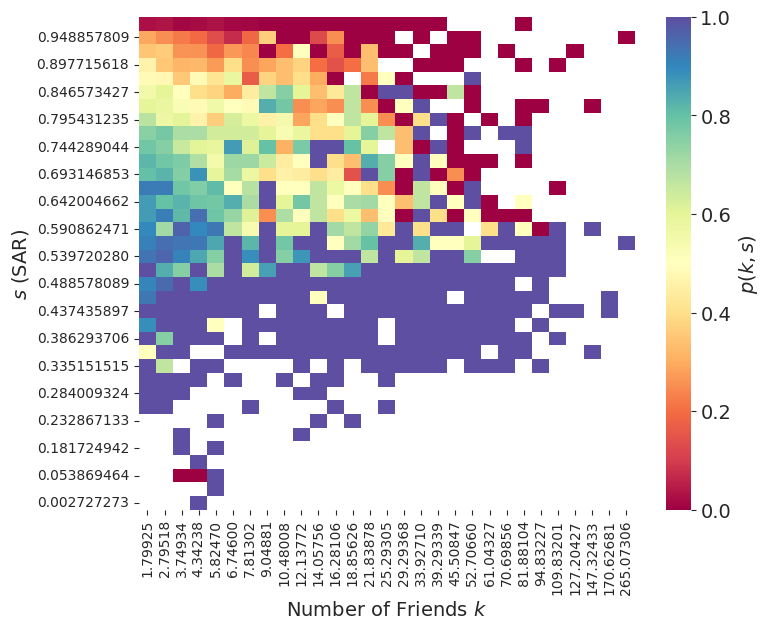

In [12]:
# Replace zeros and negative values with a small positive value (for log scale visualization)
min_positive_value = df[df['SAR_1'] > 0]['SAR_1'].min() / 10
df['SAR_1'] = df['SAR_1'].replace(to_replace=0, value=min_positive_value)

# Similarly for 'k_neighbors'
min_positive_value_k = df[df['k_neighbors'] > 0]['k_neighbors'].min() / 10
df['k_neighbors'] = df['k_neighbors'].replace(to_replace=0, value=min_positive_value_k)

# Convert 'FP' from boolean to numeric for calculation
df['FP'] = df['FP'].astype(int)

# Generating bins for 'k_neighbors' and 'IAR_1' in log scale
k_bins = np.logspace(np.log10(df['k_neighbors'].min()), np.log10(df['k_neighbors'].max()), 40)
sar_bins = np.linspace(df['SAR_1'].min(), df['SAR_1'].max(), 40)

# Creating a pivot table to calculate the proportion of 'FP' == True
# Not rounding labels, using more unique labels
pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['SAR_1'], sar_bins, labels=[f'{x:.9f}' for x in sar_bins[:-1]]),
                             columns=pd.cut(df['k_neighbors'], k_bins, labels=[f'{x:.5f}' for x in k_bins[:-1]]),
                             aggfunc=np.mean)

# Creating the heatmap
plt.figure(figsize=(8, 6.4))
sns.set_style("ticks")
ax = plt.gca()
heatmap = sns.heatmap(pivot_table, annot=False, cmap="Spectral", cbar_kws={'label': '$p(k,s)$'})

cbar = heatmap.collections[0].colorbar
cbar.set_label('$p(k,s)$', fontsize=14)
cbar.ax.tick_params(labelsize=14)

# # Set log scale for axes
# ax.set_xscale('log')
# ax.set_yscale('log')

# Manually setting x-axis ticks
# xticks = [10**i for i in range(4)]  # 10^0 to 10^3
# ax.set_xticks(xticks)
# ax.set_xticklabels([f"$10^{i}$" for i in range(4)])  # Use LaTeX formatting for powers of 10

ax.set_xlabel('Number of Friends $k$', fontsize=14)
ax.set_ylabel('$s$ (SAR)', fontsize=14)
ax.invert_yaxis()
# ax.set_xticks([])
# ax.set_yticks([])

plt.savefig('img/SAR_heatmap_election.png', dpi=1000, bbox_inches='tight')
plt.show()

In [75]:
df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/p(k,s)_df_all_interaction_IAR_election.csv")

/tmp/SLURM_23171770/ipykernel_40812/2167723637.py:18: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['IAR_1'], iar_bins, labels=[f'{x:.9f}' for x in iar_bins[:-1]]),
/tmp/SLURM_23171770/ipykernel_40812/2167723637.py:18: FutureWarning: The provided callable <function mean at 0x7f4bd472aac0> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['IAR_1'], iar_bins, labels=[f'{x:.9f}' for x in iar_bins[:-1]]),


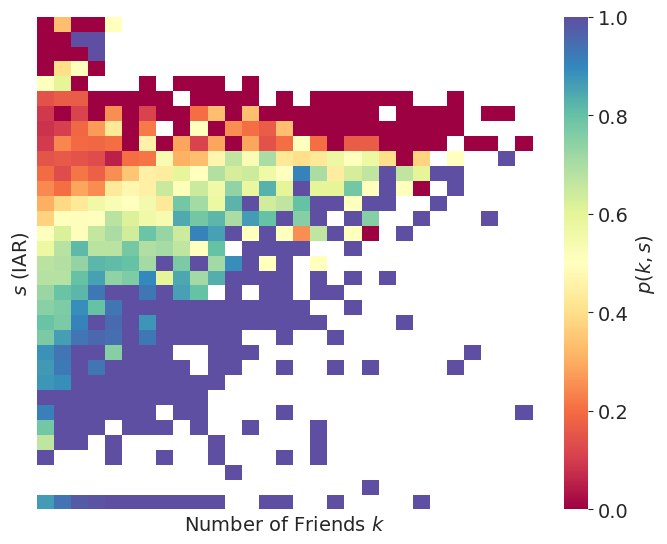

In [76]:
# Replace zeros and negative values with a small positive value (for log scale visualization)
min_positive_value = df[df['IAR_1'] > 0]['IAR_1'].min() / 10
df['IAR_1'] = df['IAR_1'].replace(to_replace=0, value=min_positive_value)

# Similarly for 'k_neighbors'
min_positive_value_k = df[df['k_neighbors'] > 0]['k_neighbors'].min() / 10
df['k_neighbors'] = df['k_neighbors'].replace(to_replace=0, value=min_positive_value_k)

# Convert 'FP' from boolean to numeric for calculation
df['FP'] = df['FP'].astype(int)

# Generating bins for 'k_neighbors' and 'IAR_1' in log scale
k_bins = np.logspace(np.log10(df['k_neighbors'].min()), np.log10(df['k_neighbors'].max()), 40)
iar_bins = np.logspace(np.log10(df['IAR_1'].min()), np.log10(df['IAR_1'].max()), 40)

# Creating a pivot table to calculate the proportion of 'FP' == True
# Not rounding labels, using more unique labels
pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['IAR_1'], iar_bins, labels=[f'{x:.9f}' for x in iar_bins[:-1]]),
                             columns=pd.cut(df['k_neighbors'], k_bins, labels=[f'{x:.5f}' for x in k_bins[:-1]]),
                             aggfunc=np.mean)

# Creating the heatmap
plt.figure(figsize=(8, 6.4))
sns.set_style("ticks")
ax = plt.gca()
heatmap = sns.heatmap(pivot_table, annot=False, cmap="Spectral", cbar_kws={'label': '$p(k,s)$'})

cbar = heatmap.collections[0].colorbar
cbar.set_label('$p(k,s)$', fontsize=14)
cbar.ax.tick_params(labelsize=14)

# # Set log scale for axes
# ax.set_xscale('log')
# ax.set_yscale('log')

# Manually setting x-axis ticks
# xticks = [10**i for i in range(4)]  # 10^0 to 10^3
# ax.set_xticks(xticks)
# ax.set_xticklabels([f"$10^{i}$" for i in range(4)])  # Use LaTeX formatting for powers of 10

ax.set_xlabel('Number of Friends $k$', fontsize=14)
ax.set_ylabel('$s$ (IAR)', fontsize=14)
ax.invert_yaxis()
ax.set_xticks([])
ax.set_yticks([])

#plt.savefig('img/IAR_heatmap_election.png', dpi=1000, bbox_inches='tight')
plt.show()

In [73]:
df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/p(k,s)_df_all_interaction_SAR_election.csv")

/tmp/SLURM_23171770/ipykernel_40812/1544777930.py:18: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['SAR_1'], sar_bins, labels=[f'{x:.9f}' for x in sar_bins[:-1]]),
/tmp/SLURM_23171770/ipykernel_40812/1544777930.py:18: FutureWarning: The provided callable <function mean at 0x7f4bd472aac0> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['SAR_1'], sar_bins, labels=[f'{x:.9f}' for x in sar_bins[:-1]]),


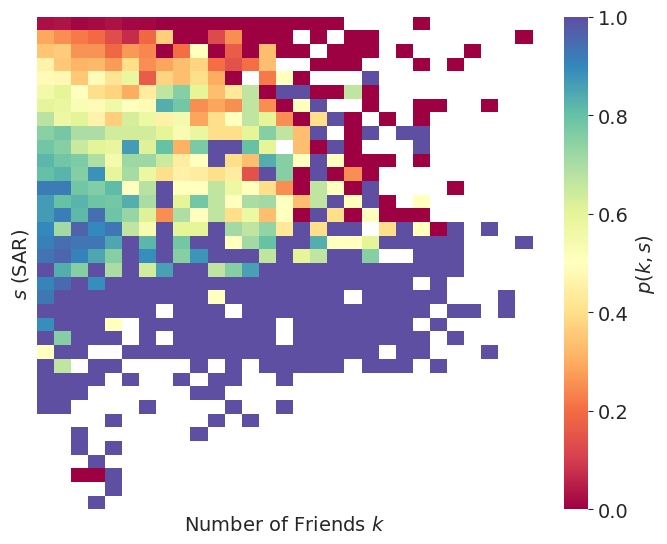

In [74]:
# Replace zeros and negative values with a small positive value (for log scale visualization)
min_positive_value = df[df['SAR_1'] > 0]['SAR_1'].min() / 10
df['SAR_1'] = df['SAR_1'].replace(to_replace=0, value=min_positive_value)

# Similarly for 'k_neighbors'
min_positive_value_k = df[df['k_neighbors'] > 0]['k_neighbors'].min() / 10
df['k_neighbors'] = df['k_neighbors'].replace(to_replace=0, value=min_positive_value_k)

# Convert 'FP' from boolean to numeric for calculation
df['FP'] = df['FP'].astype(int)

# Generating bins for 'k_neighbors' and 'IAR_1' in log scale
k_bins = np.logspace(np.log10(df['k_neighbors'].min()), np.log10(df['k_neighbors'].max()), 40)
sar_bins = np.linspace(df['SAR_1'].min(), df['SAR_1'].max(), 40)

# Creating a pivot table to calculate the proportion of 'FP' == True
# Not rounding labels, using more unique labels
pivot_table = pd.pivot_table(df, values='FP', index=pd.cut(df['SAR_1'], sar_bins, labels=[f'{x:.9f}' for x in sar_bins[:-1]]),
                             columns=pd.cut(df['k_neighbors'], k_bins, labels=[f'{x:.5f}' for x in k_bins[:-1]]),
                             aggfunc=np.mean)

# Creating the heatmap
plt.figure(figsize=(8, 6.4))
sns.set_style("ticks")
ax = plt.gca()
heatmap = sns.heatmap(pivot_table, annot=False, cmap="Spectral", cbar_kws={'label': '$p(k,s)$'})

cbar = heatmap.collections[0].colorbar
cbar.set_label('$p(k,s)$', fontsize=14)
cbar.ax.tick_params(labelsize=14)

# # Set log scale for axes
# ax.set_xscale('log')
# ax.set_yscale('log')

# Manually setting x-axis ticks
# xticks = [10**i for i in range(4)]  # 10^0 to 10^3
# ax.set_xticks(xticks)
# ax.set_xticklabels([f"$10^{i}$" for i in range(4)])  # Use LaTeX formatting for powers of 10

ax.set_xlabel('Number of Friends $k$', fontsize=14)
ax.set_ylabel('$s$ (SAR)', fontsize=14)
ax.invert_yaxis()
ax.set_xticks([])
ax.set_yticks([])

#plt.savefig('img/SAR_heatmap_election.png', dpi=1000, bbox_inches='tight')
plt.show()

### Feature importance

In [8]:
grouped_df.columns

Index(['userid', 'User IAR', 'User SAR', 'Friend IAR', 'Friend SAR',
       'User Friend Count', 'User Followers Count', 'User Favourites Count',
       'User Statuses Count', 'Friend Friend Count', 'Friend Followers Count',
       'Friend Favourites Count', 'Friend Statuses Count',
       'User Degree Centrality', 'User Eigenvector Centrality',
       'User Clustering Coefficient', 'User PageRank',
       'Friend Degree Centrality', 'Friend Eigenvector Centrality',
       'Friend Clustering Coefficient', 'Friend PageRank'],
      dtype='object')

In [22]:
grouped_df = pd.read_csv("/project2/emiliofe_74/jinyiy/susceptibility_metric/user_attribute/users_metadata_covidV3.csv")

X = grouped_df[['Friend IAR', 'Friend SAR', 'User Friend Count', 'User Followers Count', 'User Favourites Count', 'User Statuses Count', 
                'Friend Friend Count', 'Friend Followers Count', 'Friend Favourites Count', 'Friend Statuses Count',
                'User Degree Centrality', 'User Eigenvector Centrality', 'User Clustering Coefficient', 
                'Friend Degree Centrality', 'Friend Eigenvector Centrality', 'Friend Clustering Coefficient']]
y = grouped_df['User IAR']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_regressor = RandomForestRegressor(random_state=42)
rf_regressor.fit(X_train, y_train)

y_pred = rf_regressor.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")

Mean Squared Error: 0.0020032667722992992
R-squared: 0.3673058318016672


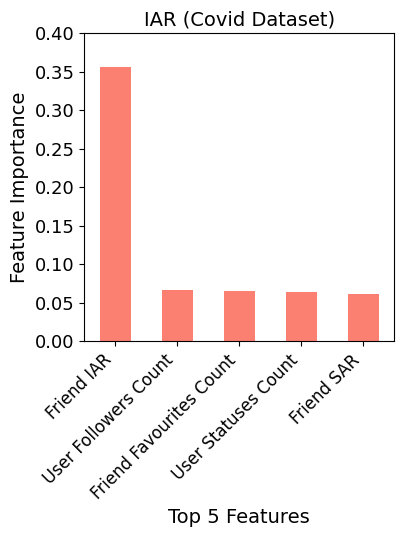

In [25]:
feature_importances = rf_regressor.feature_importances_

features = pd.Series(feature_importances, index=X_train.columns)
# features = pd.Series(feature_importances, index=features.index.str.replace('ClusteringCoefficient', 'clustering coefficient'))
# features = pd.Series(feature_importances, index=features.index.str.replace('DegreeCentrality', 'degree centrality'))
# features = pd.Series(feature_importances, index=features.index.str.replace('EigenvectorCentrality', 'eigenvector centrality'))
# features = pd.Series(feature_importances, index=features.index.str.replace('friend_IAR', 'Friend IAR'))
# features = pd.Series(feature_importances, index=features.index.str.replace('friend_SAR', 'Friend SAR'))
# features = pd.Series(feature_importances, index=features.index.str.replace('friend_favourites_count', 'Friend Favourites Count'))
# features = pd.Series(feature_importances, index=features.index.str.replace('user_statuses_count', 'User Statuses Count'))
# features = pd.Series(feature_importances, index=features.index.str.replace('user_followers_count', 'User Followers Count'))
# features = pd.Series(feature_importances, index=features.index.str.replace('friend_statuses_count', 'Friend Statuses Count'))
# features = pd.Series(feature_importances, index=features.index.str.replace('user_favourites_count', 'User Favourites Count'))
features_sorted = features.sort_values(ascending=False)
#features_sorted.to_csv("img/IAR_feature_importance_covid.csv", index=False)
features_sorted = features_sorted.head(5)
#print(features_sorted)

plt.figure(figsize=(4, 4))
features_sorted.plot(kind='bar', color=sns.color_palette("Set3")[3])
plt.title('IAR (Covid Dataset)', fontsize=14)
plt.ylabel('Feature Importance', fontsize=14)
plt.xlabel('Top 5 Features', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.tick_params(axis='y', labelsize=13)
plt.ylim(0, 0.4)

plt.savefig('img/IAR_feature_importance_covid.png', dpi=1000, bbox_inches='tight')
plt.show()

In [14]:
grouped_df = pd.read_csv("/project2/emiliofe_74/jinyiy/susceptibility_metric/user_attribute/users_metadata_covidV3.csv")

X = grouped_df[['Friend IAR', 'Friend SAR', 'User Friend Count', 'User Followers Count', 'User Favourites Count', 'User Statuses Count', 
                'Friend Friend Count', 'Friend Followers Count', 'Friend Favourites Count', 'Friend Statuses Count',
                'User Degree Centrality', 'User Eigenvector Centrality', 'User Clustering Coefficient', 
                'Friend Degree Centrality', 'Friend Eigenvector Centrality', 'Friend Clustering Coefficient']]
y = grouped_df['User SAR']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_regressor = RandomForestRegressor(random_state=42)
rf_regressor.fit(X_train, y_train)

y_pred = rf_regressor.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")

Mean Squared Error: 0.01222210777856232
R-squared: 0.3095999687704951


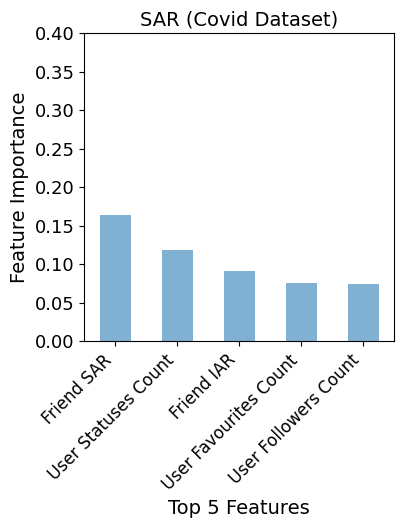

In [21]:
feature_importances = rf_regressor.feature_importances_

features = pd.Series(feature_importances, index=X_train.columns)
# features = pd.Series(feature_importances, index=features.index.str.replace('ClusteringCoefficient', 'clustering coefficient'))
# features = pd.Series(feature_importances, index=features.index.str.replace('DegreeCentrality', 'degree centrality'))
# features = pd.Series(feature_importances, index=features.index.str.replace('EigenvectorCentrality', 'eigenvector centrality'))
# features = pd.Series(feature_importances, index=features.index.str.replace('friend_IAR', 'Friend IAR'))
# features = pd.Series(feature_importances, index=features.index.str.replace('friend_SAR', 'Friend SAR'))
# features = pd.Series(feature_importances, index=features.index.str.replace('friend_favourites_count', 'Friend Favourites Count'))
# features = pd.Series(feature_importances, index=features.index.str.replace('user_statuses_count', 'User Statuses Count'))
# features = pd.Series(feature_importances, index=features.index.str.replace('user_followers_count', 'User Followers Count'))
# features = pd.Series(feature_importances, index=features.index.str.replace('user_favourites_count', 'User Favourites Count'))
features_sorted = features.sort_values(ascending=False)
#features_sorted.to_csv("img/SAR_feature_importance_covid.csv", index=False)
features_sorted = features_sorted.head(5)
#print(features_sorted)

plt.figure(figsize=(4, 4))
features_sorted.plot(kind='bar', color=sns.color_palette("Set3")[4])
plt.title('SAR (Covid Dataset)', fontsize=14)
plt.ylabel('Feature Importance', fontsize=14)
plt.xlabel('Top 5 Features', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.tick_params(axis='y', labelsize=13)
plt.ylim(0, 0.4)

plt.savefig('img/SAR_feature_importance_covid.png', dpi=1000, bbox_inches='tight')
plt.show()

### SHAP values

In [44]:
grouped_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_metadata_electionV3.csv")

X = grouped_df[['Friend IAR', 'Friend SAR', 'User Friend Count', 'User Followers Count', 'User Favourites Count', 'User Statuses Count', 
                'Friend Friend Count', 'Friend Followers Count', 'Friend Favourites Count', 'Friend Statuses Count',
                'User Degree Centrality', 'User Eigenvector Centrality', 'User Clustering Coefficient', 
                'Friend Degree Centrality', 'Friend Eigenvector Centrality', 'Friend Clustering Coefficient']]
y = grouped_df['User SAR']

In [45]:
grouped_df

,userid,User IAR,User SAR,Friend IAR,Friend SAR,User Friend Count,User Followers Count,User Favourites Count,User Statuses Count,Friend Friend Count,...,Friend Favourites Count,Friend Statuses Count,User Degree Centrality,User Eigenvector Centrality,User Clustering Coefficient,User PageRank,Friend Degree Centrality,Friend Eigenvector Centrality,Friend Clustering Coefficient,Friend PageRank
0,1.000075e+09,0.000000,1.000000,0.000000,1.000000,0.000245,0.000001,0.001357,0.000900,0.000199,...,0.033106,0.004861,0.000020,2.510000e-11,0.0,0.000012,0.000040,9.430000e-10,0.000000,0.000021
1,1.000130e+08,0.001237,0.904762,0.000081,0.991667,0.000958,0.000013,0.074053,0.008954,0.000319,...,0.014446,0.004028,0.000060,6.420000e-13,0.0,0.000035,0.000020,3.710000e-13,0.000000,0.000015
2,1.000140e+18,0.017824,0.707317,0.003800,0.654215,0.036729,0.000642,0.051096,0.053263,0.010934,...,0.049518,0.033704,0.000060,2.994020e-04,0.0,0.000012,0.000090,3.361639e-03,0.110119,0.000015
3,1.000150e+18,0.003489,0.877778,0.000022,0.986842,0.007266,0.000123,0.019928,0.013372,0.001801,...,0.001196,0.007237,0.000020,2.070000e-08,0.0,0.000011,0.000683,3.010000e-07,0.000000,0.000249
4,1.000160e+18,0.000000,1.000000,0.006683,0.849359,0.003063,0.000038,0.007640,0.005009,0.047110,...,0.156589,0.126135,0.000020,2.750000e-09,0.0,0.000009,0.000080,3.330000e-08,0.000000,0.000029
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32963,9.996650e+17,0.000160,0.970588,0.003567,0.895522,0.000177,0.000003,0.009305,0.009599,0.012132,...,0.068858,0.018748,0.000020,2.840000e-14,0.0,0.000020,0.000020,2.840000e-14,0.000000,0.000020
32964,9.997100e+17,0.000000,1.000000,0.027178,0.601751,0.000070,0.000002,0.001364,0.001390,0.038998,...,0.333751,0.249782,0.000020,1.778010e-03,0.0,0.000006,0.002530,7.810770e-02,0.039619,0.000375
32965,9.997960e+17,0.017162,0.875000,0.001875,0.936502,0.001736,0.000037,0.184140,0.014461,0.001472,...,0.044891,0.022574,0.000040,2.170000e-09,0.0,0.000020,0.000040,2.770000e-08,0.000000,0.000020
32966,9.997970e+17,0.011666,0.887218,0.009705,0.793275,0.000645,0.000025,0.011788,0.016057,0.006742,...,0.081772,0.085454,0.000161,4.260000e-06,0.0,0.000056,0.000109,2.090000e-05,0.001634,0.000038


In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_regressor = RandomForestRegressor(random_state=42)
rf_regressor.fit(X_train, y_train)

y_pred = rf_regressor.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")

Mean Squared Error: 0.010693546828087246
R-squared: 0.3895808854962014


In [47]:
sampled_X_test = X_test.sample(n=1000, replace=False)
explainer = shap.Explainer(rf_regressor)
shap_values = explainer.shap_values(sampled_X_test)

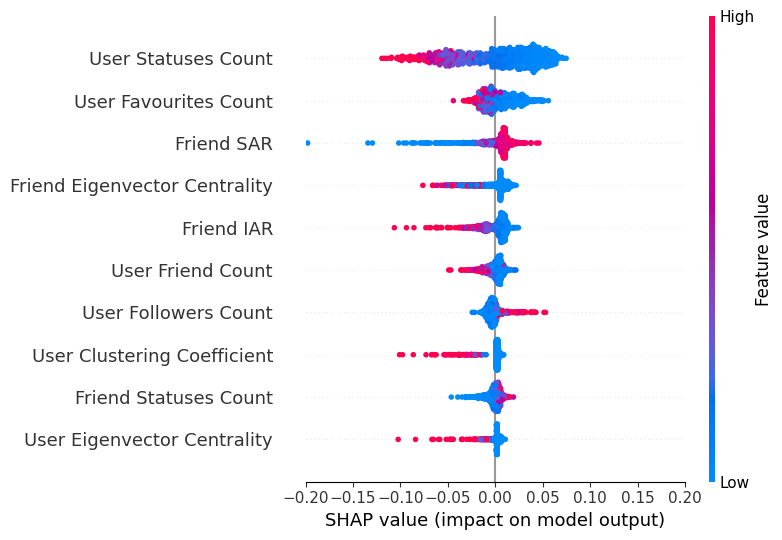

In [48]:
shap.summary_plot(shap_values, sampled_X_test, max_display=10, show=False)
ax = plt.gca()
ax.set_xlim(-0.2, 0.2) 
plt.savefig('img/SAR_shap_election.png', dpi=1000, bbox_inches='tight')
plt.show()